In [1]:
import sys # for automation and parallelization: set manual to false when run by a launcher
import json
MANUAL, SCENARIO = (True, 'base') if 'ipykernel' in sys.argv[0]\
     else (False, json.loads(sys.argv[1])['scenario'])

# START

In [2]:
import sys
sys.path.insert(0, r'../../../quetzal')

from quetzal.model import stepmodel, connectionscanmodel
from quetzal.io import excel
import geopandas as gpd
import shapely
import os
import numpy as np
import pandas as pd
if MANUAL:
    %matplotlib inline

from syspy.syspy_utils.data_visualization import bandwidth, width_series, color_series

In [3]:
qpath = r'../../'
ipath = qpath + r'inputs/'
mpath = qpath + r'scenarios/{}/models/'.format(SCENARIO)

In [4]:
var = excel.read_var(ipath + r'parameters.xlsx', scenario=SCENARIO)

In [5]:
INTRA_AREA_TO_DISTANCE_FACTOR = var[('step_distribution', 'intra_area_to_distance_factor')]

WALK_TIME_FACTOR = var[('mode_penalty', 'walk_time_factor')]
BIKE_TIME_FACTOR = var[('mode_penalty', 'bike_time_factor')]
CAR_TIME_FACTOR = var[('mode_penalty', 'car_time_factor')]

WAITING_TIME_FACTOR =  var[('pt_penalty', 'waiting_time_factor')]
TRANSFER_TIME_FACTOR = var[('pt_penalty', 'transfer_time_factor')]
ACCESS_TIME_FACTOR = var[('pt_penalty', 'access_time_factor')]
TRANSFER_PENALTY = var[('pt_penalty', 'transfer_penalty')]

KM_FARES = var['fare_km'].to_dict()

CAR_KM_FARES = var['fare_car'].to_dict()
KM_FARES['car'] = CAR_KM_FARES['fuel_cost'] + CAR_KM_FARES['other_costs']

VALUE_OF_TIME_SEC = var[('value_of_time', 'value_of_time_h')]/3600

In [6]:
var["pt_penalty"]

parameter
waiting_time_factor     1.5
transfer_time_factor      2
access_time_factor        1
transfer_penalty        600
Name: base, dtype: object

In [7]:
if var['run_mode']['mode'] != 'timetables':
    sm = stepmodel.read_zippedpickles(mpath + r'generation_distribution')
else:
    sm = connectionscanmodel.read_zippedpickles(mpath + r'generation_distribution')

zone_to_road: 100%|██████████| 22/22 [00:01<00:00, 12.16it/s]


## MaP

In [8]:
sm.los = sm.los[sm.los["route_type"]!="walk"]
sm.segments = ["volume"]

In [9]:
sm.los.loc[(sm.los['origin'] == 'zone_05') & (sm.los['destination'] == 'zone_04')][['route_types'] + [x for x in sm.los.columns if 'time' in x] + ['length', 'fare']]

,route_types,time,gtime,time_link_path,access_time,footpath_time,in_vehicle_time,waiting_time,boarding_time,length,fare
339,"(car,)",3323.819209,9977.144873,NaN,NaN,NaN,NaN,NaN,NaN,44056.536505,9.362014
4895,"(bike,)",9977.144873,9249.149228,NaN,NaN,NaN,NaN,NaN,NaN,43105.846878,0.000000
9451,"(bus,)",20197.273841,23696.772595,9019.498754,1010.307214,2866.966627,5520.0,10800.0,0,NaN,6.864040
38493,"(bus,)",21456.726646,24971.128154,8614.401508,1256.671291,4300.055355,5100.0,10800.0,0,NaN,6.884764
40612,"(bus,)",25414.661561,29587.102656,10472.441094,1010.307214,8504.354347,6300.0,9600.0,0,NaN,7.799098


In [10]:
### Compute zone-zone distances

sm.zones['area'] = sm.zones.area ## m²

distances = sm.zones.reset_index()[['index', 'lat_centroid', 'lng_centroid', 'area']]
distances['geometry'] = gpd.points_from_xy(distances['lng_centroid'], distances['lat_centroid'])
distances = distances.set_geometry('geometry').set_crs('EPSG:4326').to_crs('EPSG:2154').drop(columns=['lng_centroid', 'lat_centroid'])
distances = distances.merge(distances, how='cross', suffixes = ['_from', '_to'])
distances['distance'] = (distances['area_from'] ** 0.5) * INTRA_AREA_TO_DISTANCE_FACTOR
distances.loc[distances['index_from'] != distances['index_to'], 'distance'] = distances.apply(lambda x: shapely.distance(x['geometry_from'], x['geometry_to']), 1)
distances = distances[['index_from', 'index_to', 'distance']].rename(columns={'index_from': 'origin', 'index_to': 'destination'})

In [11]:
sm.volumes

,origin,destination,volume
0,zone_00,zone_00,510.152397
1,zone_00,zone_01,545.589559
2,zone_00,zone_02,33.679766
3,zone_00,zone_03,34.005669
4,zone_00,zone_04,59.787849
...,...,...,...
4619,zone_67,zone_63,185.196626
4620,zone_67,zone_64,538.109512
4621,zone_67,zone_65,483.048403
4622,zone_67,zone_66,524.909599


In [12]:
### Share of walk among volumes:
share_not_walking = {
    1000: 0.12,
    2000: 0.41,
    3000: 0.87,
    4000: 0.97,
    5000: 0.98, 
    np.inf: 1
}

def apply_dict(x, dict):
    for v_ in dict.keys():
        if x <= v_:
            return dict[v_]

sm.volumes = sm.volumes.merge(distances, on=['origin', 'destination'], how='left')
sm.walk_volumes = sm.volumes.copy()
sm.walk_volumes['volume'] *= (1-sm.volumes['distance'].apply(lambda x: apply_dict(x, share_not_walking)))
sm.volumes['volume'] *= sm.volumes['distance'].apply(lambda x: apply_dict(x, share_not_walking))
sm.volumes.drop(columns='distance', inplace=True)
# sm.walk_volumes.drop(columns='distance', inplace=True)

In [13]:
# TODO: gérer la MAP pour les intrazonaux des zones très grandes -> mini 25% de MAP imposée ?

In [14]:
sm.walk_volumes[sm.walk_volumes.origin==sm.walk_volumes.destination]

,origin,destination,volume,distance
0,zone_00,zone_00,0.000000,29826.229948
69,zone_01,zone_01,0.000000,25434.582642
138,zone_02,zone_02,0.000000,15161.315131
207,zone_03,zone_03,0.000000,24408.062517
276,zone_04,zone_04,0.000000,25169.608032
...,...,...,...,...
4347,zone_63,zone_63,1495.482665,1326.223999
4416,zone_64,zone_64,2413.866490,1285.117223
4485,zone_65,zone_65,577.950948,1041.077031
4554,zone_66,zone_66,1032.996314,1273.694369


## Configure Logit scales

In [15]:
var['preparation_logit'].to_dict()

{'time': -0.0005,
 'price': -0.2,
 'transfers': -0.5,
 'mode': 1,
 'pt_mode': 0.8,
 'pt_path': 0.5}

In [16]:
kwargs = var['preparation_logit'].to_dict()

sm.preparation_logit(
    **kwargs, segments=['volume'],
    route_types=['root', 'car', 'bike', 'pt'] + list(sm.links["route_type"].unique())
)

In [17]:
sm.utility_values.T

value,time,price,ntransfers,mode_utility
segment,,,,
root,-0.0005,-0.2,-0.5,1.0
volume,-0.0005,-0.2,-0.5,1.0


In [18]:
sm.logit_scales.T

route_type,root,car,bike,pt,bus,rail,tramway
segment,,,,,,,
root,1.0,0.0,0.5,0.8,0.5,0.5,0.5
volume,1.0,0.0,0.5,0.8,0.5,0.5,0.5


In [19]:
sm.mode_nests.loc['bike'] = 'root'
sm.mode_nests

segment,root,volume
route_type,,
root,NaN,NaN
car,root,root
bike,root,root
pt,root,root
bus,pt,pt
rail,pt,pt
tramway,pt,pt


In [20]:
# TODO: ajouter une valeur par défaut pour les paramètres de mode TC manquants ?
for mode in set(sm.mode_utility.index) - {"root", "pt"}:
    sm.mode_utility.loc[mode] = var['mode_utility'][mode]

sm.mode_utility

segment,root,volume
route_type,,
root,0,0
car,1,1
bike,0,0
pt,0,0
bus,0,0
rail,0,0
tramway,0,0


## Utility

In [21]:

# TODO Louison: (temps de transfer? = temps d'attente pas lié au premier moyen de transport utilisé?)
# temps de rabattement : access_time
# temps de correspondance : waiting_time
# temps d'accès : footpath_time
### et finalement : time = in_vehicle_time + access_time + footpath_time + waiting_time

# TODO : BOUCLE à crée avec les cellules dessous, à mettre au propre dans des fonctions avant

Principe: affectation par tranche et mise à jour des LOS
on découpe la demande en 10 (paramétrable) tranches et on fait 10 itérations:

- a. Logit
- b. on fait l’affectation TC et on met à jour les LOS TC
- c. on fait l’affectation CAR (AON) et on met à jour les LOS CAR
- d. on fusionne tous les LOS mis à jour et on passe à la tranche suivante

Les tranches sont de taille différente (plus grosses au début)

## A. RUN LOGIT

In [22]:
## TODO: à mettre dans networks + valider les capacités
mode_capacities = {
    'tramway': 250,
    'bus': 60,
    'rail': 400
}

sm.links['mode_capacity'] = sm.links['route_type'].map(mode_capacities)
sm.links['capacity'] = 3600 * sm.links['mode_capacity'] / sm.links['headway']

# B. ASSIGNMENT

In [ ]:
# UTILS
from quetzal.engine.road_pathfinder import (
    init_network,
    init_volumes,
    msa_roadpathfinder,
    get_car_los_time,
    to_polars
)
from quetzal.engine.msa_utils import jam_time

def _build_car_los(car_los):
    car_los['penalties'] = 0
    car_los['ntransfers'] = 0
    car_los['parking_fare'] = car_los['destination'].map(sm.zones['parking_fare'].to_dict())
    car_los['flat_fare'] = 0
    car_los['km_fare'] = car_los['length'] * KM_FARES['car'] / 1000 
    car_los['fare'] = car_los['length'] * KM_FARES['car'] / 1000 + car_los['parking_fare']
    car_los['time'] += car_los['penalties']
    car_los['route_types'] = [('car',)] * len(car_los)
    car_los['route_type'] = 'car'
    # car_los['time'] = car_los['gtime']
    # car_los['gtime'] = car_los["time"] + car_los['in_vehicle_length'] / 1000 * KM_FARES['car'] / VALUE_OF_TIME_SEC
    return car_los

def _apply_los_time_factors(los, route_types=["pt", "car", "bike", "walk"]):
    if "pt" in route_types:
        pt_mask = los['route_type'].isin(['rail', 'tramway', 'bus'])
        los.loc[pt_mask, 'time'] = los.loc[pt_mask, 'in_vehicle_time'].fillna(0) +\
            los.loc[pt_mask, 'access_time'].fillna(0)*ACCESS_TIME_FACTOR +\
            los.loc[pt_mask, 'footpath_time'].fillna(0)*ACCESS_TIME_FACTOR +\
            los.loc[pt_mask, 'waiting_time'].fillna(0)*WAITING_TIME_FACTOR +\
            los.loc[pt_mask, 'ntransfers']*TRANSFER_PENALTY+\
            los.loc[pt_mask, 'in_vehicle_congestion_penalty']+\
            los.loc[pt_mask, 'boarding_congestion_penalty']

    if "car" in route_types:
        car_mask = (los['route_type'] == 'car')
        los.loc[car_mask, 'time'] = los.loc[car_mask, 'time'] * CAR_TIME_FACTOR

    if "bike" in route_types:
        bike_mask = (los['route_type'] == 'bike')
        los.loc[bike_mask, 'time'] = los.loc[bike_mask, 'time'] * BIKE_TIME_FACTOR + 0.01 * los.loc[bike_mask, 'length'] ** 1.5

    if "walk" in route_types:
        walk_mask = (los['route_type'] == 'walk')
        los.loc[walk_mask, 'time'] = los.loc[walk_mask, 'time'] * WALK_TIME_FACTOR

    return los

In [ ]:
import math

def schema_degressif(
    n: int,
    alpha: float = 0.15,
    k_lam: float = 4.2,
    max_pct: float = 20.0,
    arrondi: int = 1,
) -> list[float]:
    """
    Génère un schéma dégressif en pourcentages (somme = 100.0) pour N tranches,
    avec plafonnement strict de chaque tranche à `max_pct` (par défaut 20.0%).
    """
    if n <= 0:
        raise ValueError("N doit être strictement positif.")
    if not (0.0 <= alpha <= 1.0):
        raise ValueError("alpha doit être compris entre 0 et 1.")
    if n * max_pct < 100.0 - 1e-9:
        raise ValueError(
            f"Impossible d'atteindre 100% avec N={n} tranches plafonnées à {max_pct}%."
        )

    lam = k_lam / n
    expo = [math.exp(-lam * i) for i in range(n)]
    p_expo = [x / sum(expo) for x in expo]
    p_unif = [1.0 / n] * n

    bruts = [(1.0 - alpha) * pe + alpha * pu for pe, pu in zip(p_expo, p_unif)]
    pcts = [x * 100.0 / sum(bruts) for x in bruts]

    # Plafonnement itératif ("water-filling") pour redistribuer l'excédent au-delà de max_pct
    plafonnes = list(pcts)
    fixes = [False] * n
    while True:
        excedent = sum(
            max(0.0, v - max_pct) for i, v in enumerate(plafonnes) if not fixes[i]
        )
        if excedent <= 1e-12:
            break
        for i in range(n):
            if not fixes[i] and plafonnes[i] >= max_pct - 1e-12:
                plafonnes[i] = max_pct
                fixes[i] = True
        libres = [i for i in range(n) if not fixes[i]]
        if not libres:
            break
        somme_libres = sum(plafonnes[i] for i in libres)
        if somme_libres > 0:
            for i in libres:
                plafonnes[i] += excedent * (plafonnes[i] / somme_libres)
        else:
            for i in libres:
                plafonnes[i] += excedent / len(libres)

    # Arrondi et ajustement sans jamais dépasser max_pct
    facteur = 10**arrondi
    arrondis = [min(max_pct, round(x * facteur) / facteur) for x in plafonnes]
    ecart = round(100.0 - sum(arrondis), arrondi)

    pas = (1.0 / facteur) if ecart > 0 else -(1.0 / facteur)
    nb_pas = int(round(abs(ecart) * facteur))
    for _ in range(nb_pas):
        if pas > 0:
            candidats = [i for i, v in enumerate(arrondis) if v + 1e-9 < max_pct]
            cible = max(candidats, key=lambda idx: plafonnes[idx] - arrondis[idx])
        else:
            candidats = [i for i, v in enumerate(arrondis) if v > 0]
            cible = max(candidats, key=lambda idx: arrondis[idx])
        arrondis[cible] = round(arrondis[cible] + pas, arrondi)

    return arrondis

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_indicators(indicators: dict, save_path: str | None = None) -> None:
    """
    Visualise le dictionnaire d'indicateurs par tranche :
    - modal_shares_i : liste de pd.Series (parts modales en %)
    - car_flow_q7 / pt_flow_q7 / mode_pt_flow_q7 : débits moyens voiture & TC
    - mode_pt_saturation_q9 : liste de pd.Series / dicts des taux de saturation par mode PT
    - mean_car_los_time / weighted_car_los_time : temps / LOS voiture (axe gauche, log)
    - mean_pt_los_time / weighted_pt_los_time : temps / LOS TC (axe droit, log)
    """
    n_steps = len(indicators["car_flow_q7"])
    steps = [f"T{i + 1}" for i in range(n_steps)]

    mode_order = ["car", "bike", "bus", "tramway", "rail"]
    mode_colors = {
        "car": "#e41a1c",
        "bike": "#ffd92f",
        "bus": "#377eb8",
        "tramway": "#4daf4a",
        "rail": "#8c510a",
    }
    df_modes = pd.DataFrame(indicators["modal_shares_i"], index=steps)[mode_order]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(
        "Suivi des indicateurs par tranche d'affectation",
        fontsize=14,
        fontweight="bold",
    )

    # 1. Parts modales empilées
    ax1 = axes[0, 0]
    df_modes.plot(
        kind="bar",
        stacked=True,
        ax=ax1,
        color=[mode_colors[m] for m in mode_order],
        edgecolor="white",
    )
    ax1.set_title("Parts modales par tranche (%)")
    ax1.set_xlabel("Tranche")
    ax1.set_ylabel("Part modale (%)")
    ax1.set_ylim(0, 100)
    ax1.legend(title="Mode", bbox_to_anchor=(1.02, 1), loc="upper left")
    ax1.grid(axis="y", linestyle="--", alpha=0.5)
    ax1.tick_params(axis="x", rotation=0)

    # 2. Débits moyens : Voiture sur axe gauche, TC global + modes PT sur axe secondaire à droite
    ax2 = axes[0, 1]
    ax2_pt = ax2.twinx()

    l1 = ax2.plot(
        steps,
        [float(x) for x in indicators["car_flow_q7"]],
        marker="o",
        linewidth=2.2,
        color=mode_colors["car"],
        label="Voiture moy (car_flow_q7)",
    )
    l2 = ax2_pt.plot(
        steps,
        [float(x) for x in indicators["pt_flow_q7"]],
        marker="s",
        linewidth=2.2,
        linestyle="-",
        color="black",
        label="TC global moy (pt_flow_q7)",
    )

    pt_lines = []
    markers = {"bus": "^", "tramway": "d", "rail": "v"}

    if indicators.get("mode_pt_flow_q7"):
        df_pt_modes = pd.DataFrame(indicators["mode_pt_flow_q7"], index=steps)
        pt_cols = [m for m in ["bus", "tramway", "rail"] if m in df_pt_modes.columns] or list(df_pt_modes.columns)
        for m in pt_cols:
            line = ax2_pt.plot(
                steps,
                [float(x) for x in df_pt_modes[m]],
                marker=markers.get(m, "x"),
                linewidth=1.8,
                linestyle="--",
                color=mode_colors.get(m),
                label=f"PT moy - {m}",
            )
            pt_lines.extend(line)

    ax2.set_title("Évolution des débits moyens (Voiture & TC)")
    ax2.set_xlabel("Tranche")
    ax2.set_ylabel("Débit moyen voiture", color=mode_colors["car"])
    ax2_pt.set_ylabel("Débit moyen TC / modes PT", color="black")
    ax2.tick_params(axis="y", labelcolor=mode_colors["car"])
    ax2_pt.tick_params(axis="y", labelcolor="black")

    lines = l1 + l2 + pt_lines
    labels = [l.get_label() for l in lines]
    ax2.legend(lines, labels, loc="upper left", fontsize=8.2)
    ax2.grid(True, linestyle="--", alpha=0.5)

    # 3. Saturation par mode PT (mode_pt_saturation_q9)
    ax3 = axes[1, 0]
    if indicators.get("mode_pt_saturation_q9"):
        df_sat = pd.DataFrame(indicators["mode_pt_saturation_q9"], index=steps)
        pt_cols_sat = [m for m in ["bus", "tramway", "rail"] if m in df_sat.columns] or list(df_sat.columns)
        for m in pt_cols_sat:
            ax3.plot(
                steps,
                [float(x) for x in df_sat[m]],
                marker=markers.get(m, "o"),
                linewidth=2,
                color=mode_colors.get(m),
                label=m,
            )
    ax3.axhline(1.0, color="gray", linestyle=":", linewidth=1.2, label="Seuil saturation = 1.0")
    ax3.set_title("Saturation par mode PT (mode_pt_saturation_q9)")
    ax3.set_xlabel("Tranche")
    ax3.set_ylabel("Taux de saturation")
    ax3.legend(title="Mode PT", loc="upper left", fontsize=8.5)
    ax3.grid(True, linestyle="--", alpha=0.5)

    # 4. Temps / LOS regroupés (Voiture à gauche, TC sur axe secondaire à droite, échelle log)
    ax4 = axes[1, 1]
    ax4_pt = ax4.twinx()

    c1 = ax4.plot(
        steps,
        [float(x) for x in indicators["mean_car_los_time"]],
        marker="o",
        linewidth=2,
        linestyle="-",
        color="crimson",
        label="Car moy (mean_car_los_time)",
    )
    extra_lines = []
    if indicators.get("weighted_car_los_time"):
        extra_lines += ax4.plot(
            steps,
            [float(x) for x in indicators["weighted_car_los_time"]],
            marker="^",
            linewidth=2,
            linestyle="--",
            color="darkred",
            label="Car pondéré (weighted_car_los_time)",
        )

    c2 = ax4_pt.plot(
        steps,
        [float(x) for x in indicators["mean_pt_los_time"]],
        marker="s",
        linewidth=2,
        linestyle="-",
        color="teal",
        label="PT moy (mean_pt_los_time)",
    )
    if indicators.get("weighted_pt_los_time"):
        extra_lines += ax4_pt.plot(
            steps,
            [float(x) for x in indicators["weighted_pt_los_time"]],
            marker="d",
            linewidth=2,
            linestyle="--",
            color="navy",
            label="PT pondéré (weighted_pt_los_time)",
        )

    ax4.set_yscale("log")
    ax4_pt.set_yscale("log")
    ax4.set_title("Temps / LOS Voiture & TC (échelle log)")
    ax4.set_xlabel("Tranche")
    ax4.set_ylabel("Temps / LOS voiture (log)", color="crimson")
    ax4_pt.set_ylabel("Temps / LOS TC (log)", color="teal")
    ax4.tick_params(axis="y", labelcolor="crimson")
    ax4_pt.tick_params(axis="y", labelcolor="teal")

    all_los_lines = c1 + c2 + extra_lines
    all_los_labels = [l.get_label() for l in all_los_lines]
    ax4.legend(all_los_lines, all_los_labels, loc="upper left", fontsize=7.8)
    ax4.grid(True, which="both", linestyle="--", alpha=0.5)

    plt.tight_layout(rect=[0, 0, 0.95, 0.96])

    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()

In [26]:
sm.los["los_uid"] = [i for i in range(len(sm.los))]
sm.los = sm.los.set_index("los_uid")

In [27]:
kpis = {
    "modal_shares_i": [],
    "volume_shares_i": [],
    "car_flow_q7": [],
    "mean_car_los_time": [],
    "weighted_car_los_time": [],
    "pt_flow_q7": [],
    "mean_pt_los_time": [],
    "weighted_pt_los_time" : [],
    "mode_pt_flow_q7": [],
    "mode_pt_saturation_q9": []
}
sm.los["boarding_congestion_penalty"] = 0
sm.los["in_vehicle_congestion_penalty"] = 0
sm.los['price'] = sm.los['fare']
sm.los = _apply_los_time_factors(sm.los)
sm.zone_to_road["length"] = sm.zone_to_road["geometry"].apply(lambda g: g.length)  # TODO Louison: à mettre dans pathfinder
sm_car_los= sm.los.loc[sm.los.route_type=="car"]
sm_car_los = _build_car_los(sm_car_los)

# VOLUMES
n_iter = 12
vshares = schema_degressif(n_iter)
i = 0

## PREPARATION
# ROAD PARAMETERS
free_flow = 'time'
default_bpr = 'time * (1 + {alpha} * (flow/capacity)**{beta})'.format(alpha=0.15, beta=4)  # road only
od_set=None
method="msa"
segments = sm.segments
time_column = "time"
access_time = "time"
vdf={'default_bpr': default_bpr, 'free_flow': free_flow}

# PT PARAMETERS
def get_boarding_bpr(row, ceiling=3):
        p = 1
        delta = 0.5
        boarding_bpr = delta * (row['boardings'] / max(row['capacity'] - row['load'], 1e-5)) ** p
        return min(boarding_bpr, ceiling)
alpha = 2
beta = 10
link_capacity_ratio = 0.95


## INIT
network = init_network(sm, method, segments, time_column, access_time)
network["capacity"] = network["capacity"].fillna(1)
network["base_flow"] = 0

pt_links = sm.links.copy()
pt_links["base_flow"] = 0
pt_links["base_boardings"] = 0

sm_los = sm.los.copy()
sm_los["base_volume"] = 0

while i < n_iter:
    print(i)
    sm_i = sm.copy()
    sm_i.volumes["volume"] = sm.volumes["volume"] * vshares[i] / 100
    # MODAL SPLIT
    sm_i.analysis_mode_utility(how='mean')
    sm_i.initialize_logit()
    sm_i.step_logit()
    sm_i.compute_los_volume()

    # temp = pd.concat([sm.los.groupby('route_type')['volume'].sum(), pd.Series({"walk": sm.walk_volumes["volume"].sum()})])
    temp = sm_i.los.groupby('route_type')['volume'].sum()
    # print("volume_split: ", temp)
    kpis["volume_shares_i"].append(temp)
    kpis["modal_shares_i"].append(100 * temp / temp.sum())

    car = sm_i.copy()  # contient 1 seule tranche de volumes
    car.car_los = car.los.loc[(car.los['route_type'] == 'car')&(car.los['pathfinder_session'] != 'intrazonal')]
    car.volumes = car.los.groupby(["origin", "destination"], as_index=False)[["volume"]].sum()

    ### ROAD ASSIGNMENT
    volumes = car.volumes
    loaded_links, car_los, rel_gap = msa_roadpathfinder(
        network,
        volumes,
        segments=segments,
        method=method,
        time_col=time_column,
        maxiters=1,
        num_cores=1,
        return_car_los=True
    )

    # loaded_links["flow"] = loaded_links["flow"] + loaded_links["base_flow"]
    loaded_links['time'] = jam_time(to_polars(loaded_links), vdf, 'flow', time_col=time_column)

    ### MAJ CAR_LOS
    time_dict = loaded_links['time'].to_dict()
    car_los = get_car_los_time(car_los, time_dict)
    car.car_los["time"] = car_los["time"]

    kpis["car_flow_q7"].append(loaded_links["flow"].quantile(0.7))
    kpis["mean_car_los_time"].append(car.car_los['time'].quantile(0.7))
    kpis["weighted_car_los_time"].append((car.car_los['time'] * car.car_los["volume"]).sum()/car.car_los["volume"].sum())

    ### PT ASSIGNMENT
    pt = sm_i.copy()
    pt.pt_los = pt.los.loc[(~(pt.los['route_type'].isin(['walk', 'car', 'bike'])))&(pt.los['pathfinder_session'] != 'intrazonal')]
    kpis["mean_pt_los_time"].append(pt.los['time'].mean())
    kpis["weighted_pt_los_time"].append((pt.los['time'] * pt.los["volume"]).sum()/pt.los["volume"].sum())

    pt.links = pt_links.copy()
    pt.step_pt_assignment(
        on_road_links=False, boardings=True, alightings=True, transfers=True
    )

    ## Congestion TC 
    ## 1. en ligne (links): ctime = time * (1 + alpha * (volume / capacity)**beta)
    ##      (Cela correspond en fait à un temps généralisé)
    ## 2. aux arrêts : boarding_ctime = waiting_time * (1 + delta * (boardings / remaining_capacity)**p)
    congested_links = pt.links
    congested_links['load'] = congested_links['load'] + congested_links["base_flow"]
    congested_links['boardings'] = congested_links['boardings'] + congested_links["base_boardings"]
    congested_links['bpr'] = 1 + alpha * ((congested_links['load'] / (link_capacity_ratio*congested_links['capacity'])) ** beta)
    congested_links['ctime'] = congested_links['time'] * congested_links['bpr']
    congested_links['boarding_ctime'] = congested_links["headway"]/2 * (1 + congested_links.apply(get_boarding_bpr, axis=1))


    ## UPDATE PT LOS
    d = (congested_links['ctime'] - congested_links['time']).to_dict()
    pt.pt_los['in_vehicle_congestion_penalty'] = pt.pt_los['link_path'].apply(
        lambda l: 0.5 * sum([d.get(t, 0) for t in l]) if isinstance(l, list) else 0
    )
    d_boarding = (congested_links['boarding_ctime'] - congested_links["headway"]/2).to_dict()
    pt.pt_los['boarding_congestion_penalty'] = pt.pt_los['boarding_links'].apply(
        lambda l: 5 * sum([d_boarding.get(t, 0) for t in l]) if isinstance(l, list) else 0
    )

    kpis["pt_flow_q7"].append(congested_links["load"].quantile(0.7))
    kpis["mode_pt_flow_q7"].append(congested_links.groupby("route_type")["load"].quantile(0.7))
    congested_links["saturation"] = congested_links["load"]/congested_links["capacity"]
    kpis["mode_pt_saturation_q9"].append(congested_links.groupby("route_type")["saturation"].quantile(0.9))

    ## REBUILD FULL LOS
    sm.los = pd.concat(
        [
            car.car_los,
            sm.los.loc[(sm.los['route_type'] == 'bike')&(sm.los['pathfinder_session'] != 'intrazonal')],
            pt.pt_los,
            sm.los.loc[sm.los['pathfinder_session'] == 'intrazonal']
            ]
    ).reset_index().set_index("los_uid")

    sm.los['price'] = sm.los['fare']
    sm.los = _apply_los_time_factors(sm.los, route_types=["pt", "car"])
    pt_los = sm.los[~(sm.los['route_type'].isin(['walk', 'car', 'bike']))&(pt.los['pathfinder_session'] != 'intrazonal')]
    # kpis["mean_pt_los_time"].append(pt_los['time'].mean())
    # kpis["weighted_pt_los_time"].append((pt_los['time'] * pt_los["volume"]).sum()/pt_los["volume"].sum())

    #### ADD LOAD TO BASE LOAD FOR NEXT ITER
    network["base_flow"] = loaded_links.set_index("level_0")["flow"] # déjà cumulé
    pt_links["base_flow"] = pt.links["load"]  # déjà cumulé
    pt_links["base_boardings"] = pt.links["boardings"]  # déjà cumulé
    sm_los["base_volume"] += sm_i.los["volume"].fillna(0)  # cumul
    # print("cumul vol split: ", sm_los.groupby("route_type")["base_volume"].sum())
    # print(kpis)

    i += 1


0


volume: 100%|██████████| 1/1 [00:02<00:00,  2.09s/it]


1


volume: 100%|██████████| 1/1 [00:01<00:00,  1.99s/it]


2


volume: 100%|██████████| 1/1 [00:01<00:00,  1.84s/it]


... (14 outputs left out)

10


volume: 100%|██████████| 1/1 [00:01<00:00,  1.75s/it]


11


volume: 100%|██████████| 1/1 [00:01<00:00,  1.54s/it]


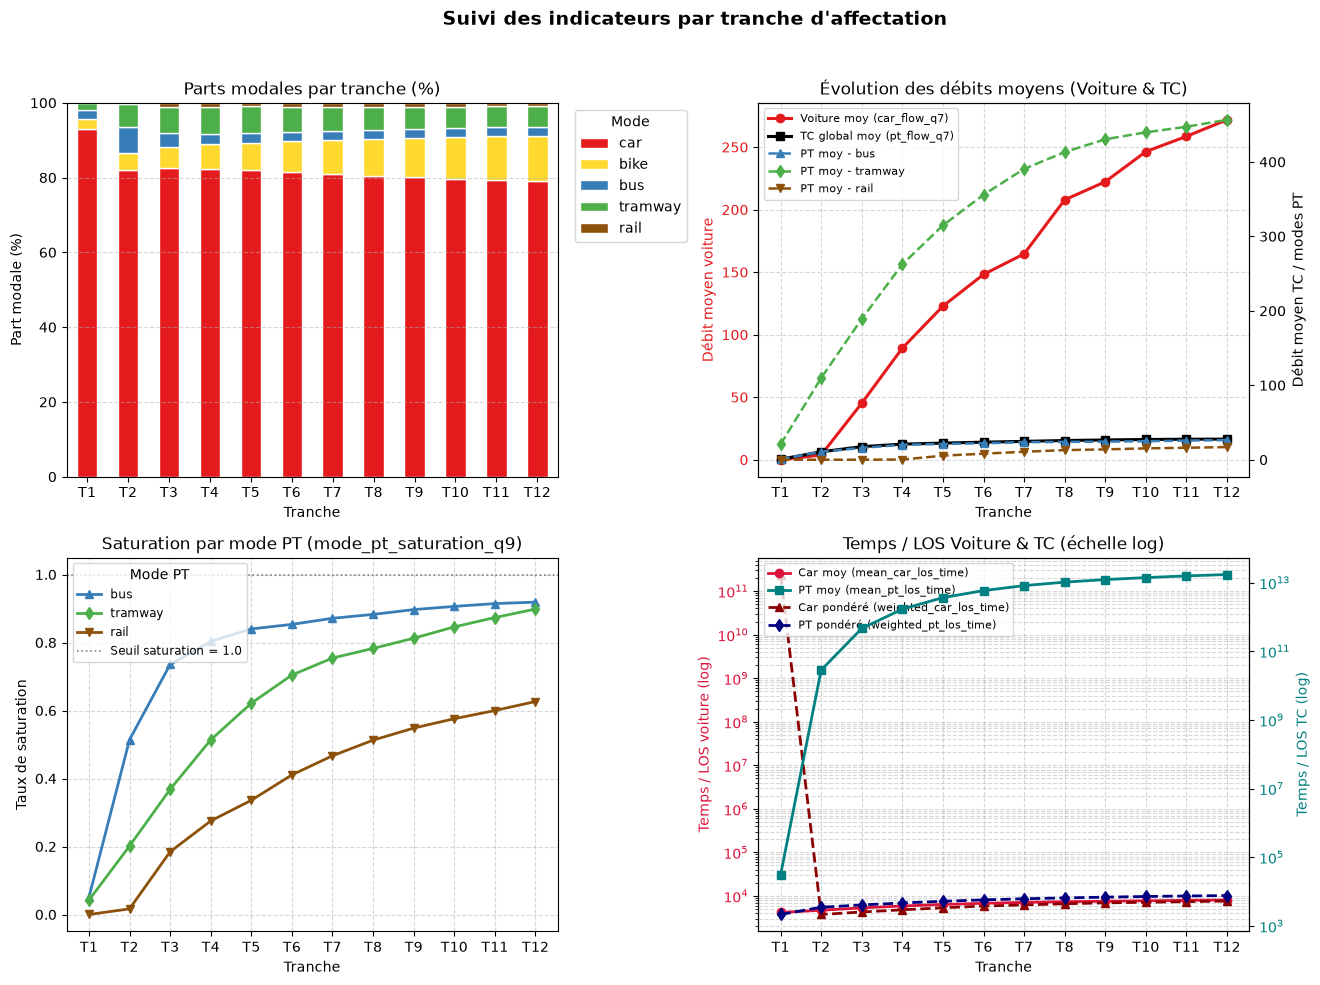

In [28]:
plot_indicators(kpis, save_path=None)

### Bike

In [34]:
# # BIKE not needed in the loop as congestion does not impact bike
# bike = sm.copy()
# bike.car_los = bike.los.loc[bike.los['route_type'] == 'bike']
# bike.step_car_assignment()
# bike.road_links = bike.road_links.drop(columns=[('volume', 'car')]).rename(columns={('all', 'car'): 'volume_bike'})

### Compute modal share

In [35]:
temp = pd.concat([sm_los.groupby('route_type')['base_volume'].sum(), pd.Series({"walk": sm.walk_volumes["volume"].sum()})])
100 * temp / temp.sum()

bike        5.741681
bus         3.309377
car        78.683423
rail        0.681998
tramway     5.321236
walk        6.262285
dtype: float64

# EXPORT

In [31]:
# car.road_links['width_cv'] = width_series(car.road_links['volume_car'])
# car.road_links['color_cv'] = color_series(car.road_links['volume_car'], colors=["#210040", "#CFFF20"])
# car.road_links['width_bv'] = width_series(car.road_links['volume_bike'])
# car.road_links['color_bv'] = color_series(car.road_links['volume_bike'], colors=["#030F0D", "#6AE1FF"])
# car.road_links['width_congestion'] = width_series(car.road_links['congestion'])
# car.road_links['color_congestion'] = color_series(car.road_links['congestion'], colors=["#FFF7F7", "#B81313"])

# pt.links['width_vol'] = width_series(pt.links['load'])
# pt.links['color_vol'] = color_series(pt.links['load'], colors=["#210040", "#CFFF20"])
# pt.links['width_congestion'] = width_series(pt.links['congestion'])
# pt.links['color_congestion'] = color_series(pt.links['width_congestion'], colors=["#FFF7F7", "#B81313"])

In [32]:
# car.road_links.drop(columns='index').to_file('../../scenarios/{}/outputs/loaded_road_links.geojson'.format(SCENARIO))
# pt.links.to_file('../../scenarios/{}/outputs/pt_loaded_links.geojson'.format(SCENARIO))

In [33]:
end_of_notebook

NameError: name 'end_of_notebook' is not defined

In [ ]:
car.car_los = car.los.loc[car.los['route_type'] == 'car']
car.volumes

### bike = sm.copy()
### bike.car_los = bike.los.loc[bike.los['route_type'] == 'bike']
### bike.step_car_assignment()

,origin,destination,volume
0,zone_00,zone_00,519.720823
1,zone_00,zone_01,556.224143
2,zone_00,zone_02,34.601580
3,zone_00,zone_03,35.038249
4,zone_00,zone_04,61.429419
...,...,...,...
4619,zone_67,zone_63,194.918432
4620,zone_67,zone_64,666.183670
4621,zone_67,zone_65,301.423003
4622,zone_67,zone_66,67.116162


In [ ]:
sm.road_links["capacity"] = sm.road_links['lanes']*sm.road_links['speed']/(sm.road_links['length']/1000) ### TODO Louison : à partir de vitesse max et lanes
sm.zone_to_road["length"] = sm.zone_to_road.geometry.apply(lambda g: g.length)
car = sm.copy()
CAR_OCCUPANCY_RATE = 1.5
# CARS
car_los = sm.los.loc[sm.los['pathfinder_session']=='car_aon']
car_los['volume'] *= 1 / CAR_OCCUPANCY_RATE
car.volumes = car_los[["origin", "destination", "volume"]]

# car.step_road_pathfinder(method='aon', segments=["volume"])
car.step_road_pathfinder(method='aon', segments=["volume"], tolerance=10) # pour les itérations intermédiaires, pas besoin d’un relgap à 0.01%

# TODO Louison: remplacer roadpathfinder MSA par un simple AON + mise à jour des temps sur les road_links à partir des courbes BPR T0*(1+\a * (T/C)**\b)

In [ ]:
sm.pt_los = sm.los[~(sm.los['route_type'].isin(['walk', 'car', 'bike']))]

# PT ASSIGNMENT
sm.step_pt_assignment(
    on_road_links=False, boardings=True, alightings=True, transfers=True
)

# compute TC congested gtime
alpha = 0.15
beta = 4
sm.links["capacity"] = 0.1 
sm.links["time"] = sm.links["time"] * (1 + alpha * sm.links["load"] / sm.links["capacity"]) ** beta

# update pt_los with congested time
d = sm.links["time"].to_dict()
sm.pt_los['in_vehicle_time'] = sm.pt_los['link_path'].apply(lambda ls: sum([d[t] for t in ls]))
cols = [
    'access_time',
    'footpath_time',
    'waiting_time',
    'boarding_time',
    'in_vehicle_time',
]

sm.pt_los['time'] = sm.pt_los[cols].T.sum()

  0%|          | 0/1 [00:00<?, ?it/s]

volume: 100%|██████████| 1/1 [00:01<00:00,  1.86s/it]


# C. CAR ASSIGNMENT

In [ ]:
sm.road_links["capacity"] = 1 ### TODO Louison : à partir de vitesse max et lanes

In [ ]:
sm.zone_to_road["length"] = sm.zone_to_road.geometry.apply(lambda g: g.length)

In [ ]:
car = sm.copy()
CAR_OCCUPANCY_RATE = 1.5  # TODO Louison: valeur de l'occupation moyenne des voitures 
# CARS
car_los = sm.los.loc[sm.los['pathfinder_session']=='car_aon']
car_los['volume'] *= 1 / CAR_OCCUPANCY_RATE
car.volumes = car_los[["origin", "destination", "volume"]]

# car.step_road_pathfinder(method='aon', segments=["volume"])
car.step_road_pathfinder(method='msa', segments=["volume"], tolerance=10) # pour les itérations intermédiaires, pas besoin d’un relgap à 0.01%

# TODO Louison: remplacer roadpathfinder MSA par un simple AON + mise à jour des temps sur les road_links à partir des courbes BPR T0*(1+\a * (T/C)**\b)

# D. MERGE

In [ ]:
#TODO Louison: merge update car los, pt-los, with the rest (bike)
#TODO Louison: back to logit (boucle)

# TOZIPPEDPICKLES

In [ ]:
# TODO: lighten los

In [ ]:
sm.to_zippedpickles(
    mpath + '{scen}/assignment'.format(scen=SCENARIO), 
)

In [ ]:
end_of_notebook

# CONTROL

In [ ]:
temp = sm.los[sm.los['origin']==sm.los['destination']]
round(
    temp.groupby('route_type')[['pt_captive', 'car_owners', 'moto_owners']].sum().T.sum() /\
    temp[['pt_captive', 'car_owners', 'moto_owners']].sum().T.sum() * 100
)

In [ ]:
round(
    sm.los.groupby('route_type')[['pt_captive', 'car_owners', 'moto_owners']].sum().T.sum() /\
    sm.los[['pt_captive', 'car_owners', 'moto_owners']].sum().T.sum() * 100
)

In [ ]:
round(
    sm.los.groupby('route_type')[['pt_captive', 'car_owners', 'moto_owners']].sum() /\
    sm.los[['pt_captive', 'car_owners', 'moto_owners']].sum() * 100
)